# Week 01 · Chunk (3 Strategies) → Build Vector Index

**Objective**: Transform crawled docs into retrieval chunks using three strategies, embed with OpenRouter/OpenAI, build ChromaDB persistent index.

**Architecture**: Uses chunking functions from `domain.chunk` and `application.ingest_doc`

**Provider Support**: Uses OpenRouter unified API (access OpenAI, Anthropic, Google, etc. with one key) or direct OpenAI


In [1]:
# Cell 1: Setup & Installations
import sys

print("📦 Checking required packages...")
required = [
    "langchain",
    "langchain_openai",
    "langchain_community",
    "langchain_text_splitters",
    "chromadb",
    "tiktoken",
    "python-dotenv"
]

missing = []
for pkg in required:
    try:
        __import__(pkg.replace("-", "_"))
    except ImportError:
        missing.append(pkg)

if missing:
    print(f"Installing missing packages: {missing}")
    %pip install -q {" ".join(missing)}

print("✅ Packages ready")


📦 Checking required packages...


C:\Users\naduk\AppData\Local\Temp\ipykernel_12292\419074611.py:18: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  __import__(pkg.replace("-", "_"))
d:\portfolio projects\hospital-system\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Installing missing packages: ['python-dotenv']
Note: you may need to restart the kernel to use updated packages.
✅ Packages ready


d:\portfolio projects\hospital-system\.venv\Scripts\python.exe: No module named pip


In [2]:
# Cell 2: Imports & Environment Setup
import os
import sys
import json
import random
from pathlib import Path
from dotenv import load_dotenv

# Add project root src to path
notebook_dir = Path.cwd()
project_root = notebook_dir.parent if (notebook_dir.parent / "src").exists() else notebook_dir
sys.path.insert(0, str(project_root / "src"))

# Load environment
load_dotenv(project_root / ".env")

# Check for API key (OpenRouter preferred, OpenAI as fallback)
openrouter_key = os.getenv("OPENROUTER_API_KEY")
openai_key = os.getenv("OPENAI_API_KEY")

if not openrouter_key and not openai_key:
    raise EnvironmentError(
        "❌ No API key found!\n"
        "   Add OPENROUTER_API_KEY (recommended) or OPENAI_API_KEY to .env"
    )

# Load configuration
from utils.config_utils import (
    CRAWL_OUT_DIR, VECTOR_DIR, EMBEDDING_MODEL, PROVIDER
)

random.seed(42)

provider = "OpenRouter" if openrouter_key else "OpenAI"
print("✅ Environment loaded")
print(f"🌐 Provider: {provider}")
print(f"📁 Project root: {project_root}")
print(f"📁 Crawl directory: {CRAWL_OUT_DIR}")
print(f"📁 Vector store directory: {VECTOR_DIR}")


✅ Environment loaded
🌐 Provider: OpenRouter
📁 Project root: d:\portfolio projects\hospital-system
📁 Crawl directory: D:\portfolio projects\hospital-system\data
📁 Vector store directory: D:\portfolio projects\hospital-system\data\vectorstore


## Import Chunking Services

Using chunking functions from application / domain layer:
- `semantic_chunk`: Splits by markdown heading hierarchy
- `fixed_chunk`: Uniform fixed token chunks with overlap
- `sliding_chunk`: Overlapping window chunks for high recall


In [3]:
# Cell 3: Import Chunking Services
from application.ingest_doc import (
    semantic_chunk,
    fixed_chunk,
    sliding_chunk
)

print("✅ Chunking services loaded from service layer")
print("📍 Location: application.ingest_doc / domain.chunk")
print("\n🎯 Available strategies:")
print("   1. semantic_chunk  - Split by heading structure")
print("   2. fixed_chunk     - Uniform token chunks with overlap")
print("   3. sliding_chunk   - Overlapping windows for better recall")


✅ Chunking services loaded from service layer
📍 Location: application.ingest_doc / domain.chunk

🎯 Available strategies:
   1. semantic_chunk  - Split by heading structure
   2. fixed_chunk     - Uniform token chunks with overlap
   3. sliding_chunk   - Overlapping windows for better recall


## Load Corpus


In [4]:
# Cell 4: Load Corpus
jsonl_path = CRAWL_OUT_DIR / "nawaloka_docs.jsonl"

# Fallback check if stored in notebooks/data
if not jsonl_path.exists():
    fallback_path = project_root / "notebooks" / "data" / "nawaloka_docs.jsonl"
    if fallback_path.exists():
        jsonl_path = fallback_path

if not jsonl_path.exists():
    raise FileNotFoundError(f"❌ Corpus not found at {jsonl_path}. Run 01_web_crawling.ipynb first.")

with open(jsonl_path, "r", encoding="utf-8") as f:
    documents = [json.loads(line) for line in f]

print(f"✅ Loaded {len(documents)} documents from: {jsonl_path}")
print(f"📊 Total content size: {sum(len(d['content']) for d in documents):,} chars")


✅ Loaded 55 documents from: D:\portfolio projects\hospital-system\data\nawaloka_docs.jsonl
📊 Total content size: 1,980,109 chars


## Apply Chunking Strategies


In [5]:
# Cell 5: Cleanup Vector Store (prevents corruption)
import shutil

# Remove existing vector store to prevent corruption issues
if VECTOR_DIR.exists():
    print(f"🗑️  Removing existing vector store: {VECTOR_DIR}")
    shutil.rmtree(VECTOR_DIR, ignore_errors=True)
    print("   ✅ Cleaned up")

# Create fresh directory
VECTOR_DIR.mkdir(parents=True, exist_ok=True)
print(f"📁 Fresh vector directory ready: {VECTOR_DIR}")


🗑️  Removing existing vector store: D:\portfolio projects\hospital-system\data\vectorstore
   ✅ Cleaned up
📁 Fresh vector directory ready: D:\portfolio projects\hospital-system\data\vectorstore


2026-11-06 18:29:28,816 - domain.chunk.chunker - INFO - Starting semantic chunk with 55 documents


🔄 Running semantic chunking...


2026-11-06 18:29:29,026 - utils.token_utils - INFO - encoding by mode : gpt-4
2026-11-06 18:29:29,032 - utils.token_utils - INFO - There are 18807 tokens.
2026-11-06 18:29:29,130 - utils.token_utils - INFO - encoding by mode : gpt-4
2026-11-06 18:29:29,130 - utils.token_utils - INFO - There are 177 tokens.
2026-11-06 18:29:29,130 - utils.token_utils - INFO - encoding by mode : gpt-4
2026-11-06 18:29:29,130 - utils.token_utils - INFO - There are 66 tokens.
2026-11-06 18:29:29,130 - utils.token_utils - INFO - encoding by mode : gpt-4
2026-11-06 18:29:29,130 - utils.token_utils - INFO - There are 46 tokens.
2026-11-06 18:29:29,136 - utils.token_utils - INFO - encoding by mode : gpt-4
2026-11-06 18:29:29,136 - utils.token_utils - INFO - There are 37 tokens.
2026-11-06 18:29:29,136 - utils.token_utils - INFO - encoding by mode : gpt-4
2026-11-06 18:29:29,136 - utils.token_utils - INFO - There are 45 tokens.
2026-11-06 18:29:29,136 - utils.token_utils - INFO - encoding by mode : gpt-4
2026-1
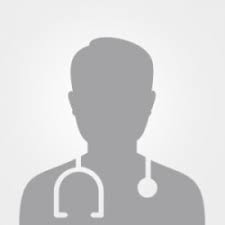
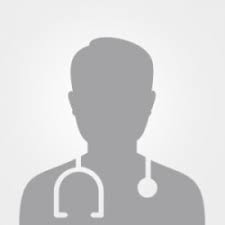
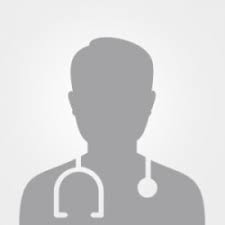
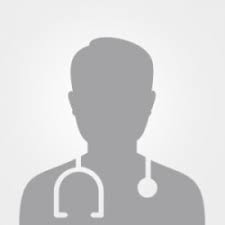
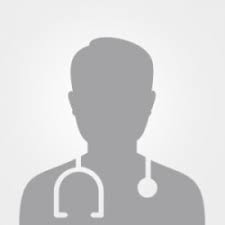
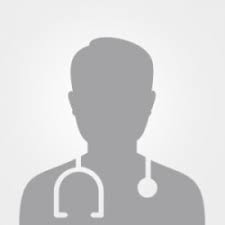
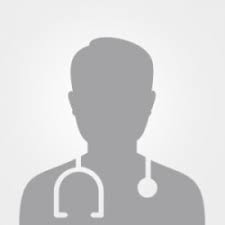
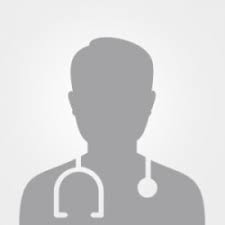
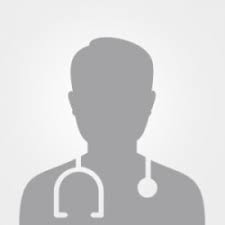
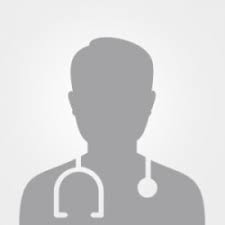
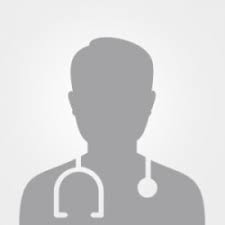
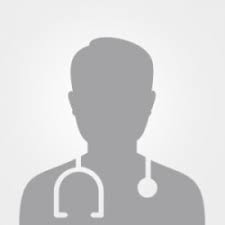
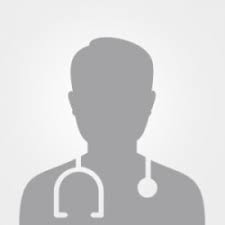
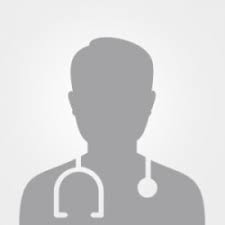
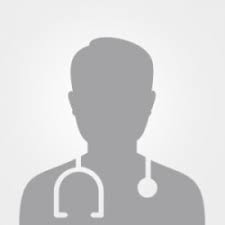
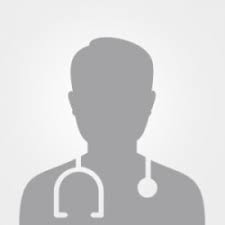
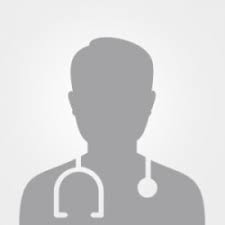
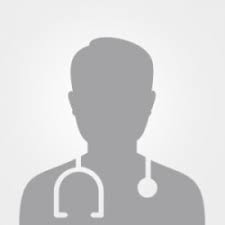
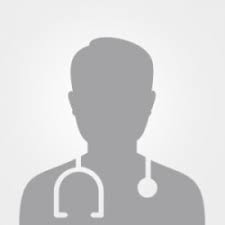
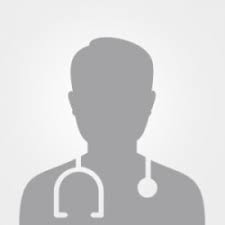
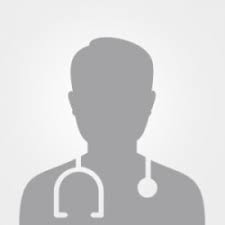
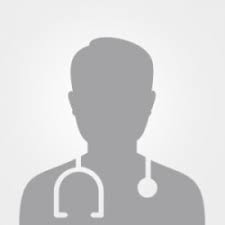
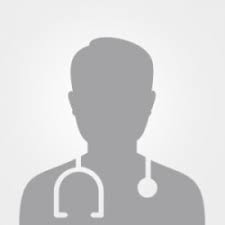
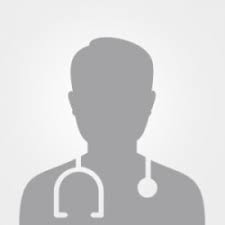
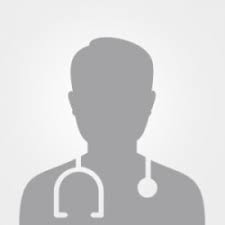
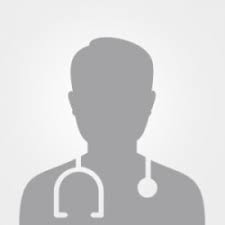
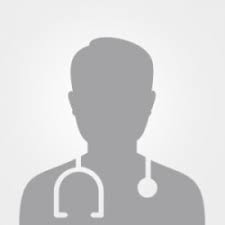
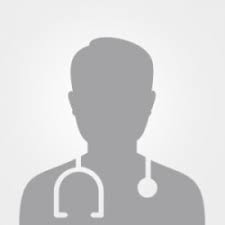
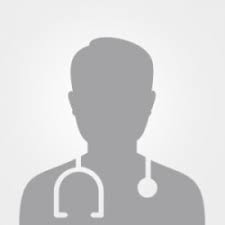
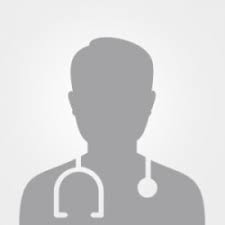
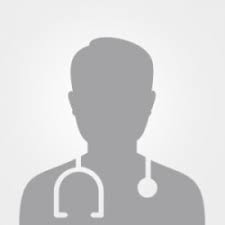
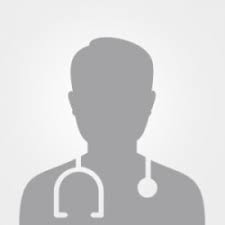
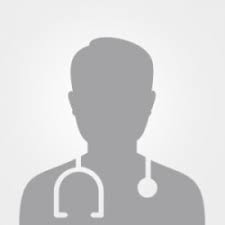
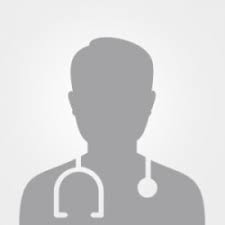
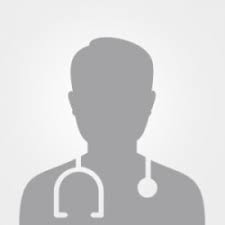
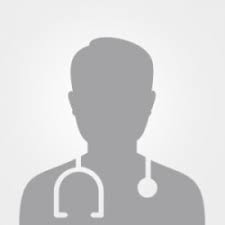
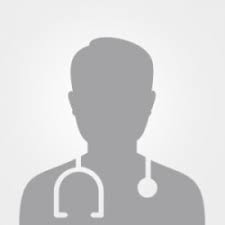
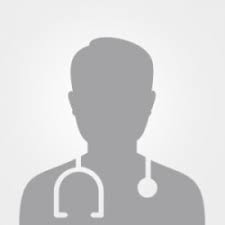
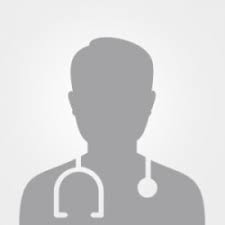

✅ Semantic chunking complete: 1399 chunks
💾 Saved to: D:\portfolio projects\hospital-system\data\chunks_semantic.jsonl


In [6]:
# Cell 6: Semantic Chunking (using service!)
print("🔄 Running semantic chunking...")
semantic_chunks = semantic_chunk(documents)

# Save
semantic_path = CRAWL_OUT_DIR / "chunks_semantic.jsonl"
with open(semantic_path, "w", encoding="utf-8") as f:
    for chunk in semantic_chunks:
        f.write(json.dumps(chunk, ensure_ascii=False) + "\n")

print(f"✅ Semantic chunking complete: {len(semantic_chunks)} chunks")
print(f"💾 Saved to: {semantic_path}")


In [7]:
# Cell 7: Fixed-Window Chunking (using service!)
print("🔄 Running fixed-window chunking...")
fixed_chunks = fixed_chunk(documents)

# Save
fixed_path = CRAWL_OUT_DIR / "chunks_fixed.jsonl"
with open(fixed_path, "w", encoding="utf-8") as f:
    for chunk in fixed_chunks:
        f.write(json.dumps(chunk, ensure_ascii=False) + "\n")

avg_tokens = sum(c.get("token_count", 0) for c in fixed_chunks) / len(fixed_chunks) if fixed_chunks else 0
print(f"✅ Fixed chunking complete: {len(fixed_chunks)} chunks")
print(f"📊 Avg token count: {avg_tokens:.1f}")
print(f"💾 Saved to: {fixed_path}")


2026-11-06 18:29:35,655 - domain.chunk.chunker - INFO - Starting Fixed chunk with 55 documents
2026-11-06 18:29:35,829 - utils.token_utils - INFO - encoding by mode : gpt-4


🔄 Running fixed-window chunking...


2026-11-06 18:29:35,843 - utils.token_utils - INFO - There are 108 tokens.
2026-11-06 18:29:35,843 - utils.token_utils - INFO - encoding by mode : gpt-4
2026-11-06 18:29:35,843 - utils.token_utils - INFO - There are 2 tokens.
2026-11-06 18:29:35,843 - utils.token_utils - INFO - encoding by mode : gpt-4
2026-11-06 18:29:35,843 - utils.token_utils - INFO - There are 2051 tokens.
2026-11-06 18:29:35,843 - utils.token_utils - INFO - encoding by mode : gpt-4
2026-11-06 18:29:35,843 - utils.token_utils - INFO - There are 2300 tokens.
2026-11-06 18:29:35,843 - utils.token_utils - INFO - encoding by mode : gpt-4
2026-11-06 18:29:35,843 - utils.token_utils - INFO - There are 2325 tokens.
2026-11-06 18:29:35,843 - utils.token_utils - INFO - encoding by mode : gpt-4
2026-11-06 18:29:35,843 - utils.token_utils - INFO - There are 1752 tokens.
2026-11-06 18:29:35,843 - utils.token_utils - INFO - encoding by mode : gpt-4
2026-11-06 18:29:35,843 - utils.token_utils - INFO - There are 7 tokens.
2026-11

✅ Fixed chunking complete: 1150 chunks
📊 Avg token count: 1147.0
💾 Saved to: D:\portfolio projects\hospital-system\data\chunks_fixed.jsonl


In [8]:
# Cell 8: Sliding-Window Chunking (using service!)
print("🔄 Running sliding-window chunking...")
sliding_chunks = sliding_chunk(documents)

# Save
sliding_path = CRAWL_OUT_DIR / "chunks_sliding.jsonl"
with open(sliding_path, "w", encoding="utf-8") as f:
    for chunk in sliding_chunks:
        f.write(json.dumps(chunk, ensure_ascii=False) + "\n")

print(f"✅ Sliding chunking complete: {len(sliding_chunks)} chunks")
print(f"💾 Saved to: {sliding_path}")


🔄 Running sliding-window chunking...
✅ Sliding chunking complete: 1963 chunks
💾 Saved to: D:\portfolio projects\hospital-system\data\chunks_sliding.jsonl


## Spot-Check Samples


In [9]:
# Cell 9: Spot-Check Samples
print("🔍 Spot-Check: 2 samples from each strategy\n")

def print_sample(chunk, strategy_name):
    print(f"**{strategy_name}** chunk:")
    print(f"  URL: {chunk.get('url', 'N/A')}")
    print(f"  Strategy: {chunk.get('strategy', 'N/A')}")
    print(f"  Text length: {len(chunk.get('text', ''))} chars")
    preview = chunk.get("text", "").replace("\n", " ")[:100]
    print(f"  Preview: {preview}...")
    print()

print("=" * 60)
print("SEMANTIC SAMPLES")
print("=" * 60)
for chunk in random.sample(semantic_chunks, min(2, len(semantic_chunks))):
    print_sample(chunk, "Semantic")

print("=" * 60)
print("FIXED-WINDOW SAMPLES")
print("=" * 60)
for chunk in random.sample(fixed_chunks, min(2, len(fixed_chunks))):
    print_sample(chunk, "Fixed")

print("=" * 60)
print("SLIDING-WINDOW SAMPLES")
print("=" * 60)
for chunk in random.sample(sliding_chunks, min(2, len(sliding_chunks))):
    print_sample(chunk, "Sliding")


🔍 Spot-Check: 2 samples from each strategy

SEMANTIC SAMPLES
**Semantic** chunk:
  URL: https://www.nawaloka.com/doctorprofile/D1866
  Strategy: semantic
  Text length: 3999 chars
  Preview: Bookings](data:image/jpeg;base64,/9j/4AAQSkZJRgABAQAAAQABAAD/4gHYSUNDX1BST0ZJTEUAAQEAAAHIAAAAAAQwAAB...

**Semantic** chunk:
  URL: https://www.nawaloka.com/physiotherapy
  Strategy: semantic
  Text length: 240 chars
  Preview: ## Supporting Your Journey Back to Movement   ![Pain management](https://media.istockphoto.com/id/14...

FIXED-WINDOW SAMPLES
**Fixed** chunk:
  URL: https://www.nawaloka.com/aboutus
  Strategy: fixed
  Text length: 43 chars
  Preview: Admission Reservation  Reserve an Admission...

**Fixed** chunk:
  URL: https://www.nawaloka.com/lasik-advanced-eye-care-centre
  Strategy: fixed
  Text length: 779 chars
  Preview: HR8FWS2lOQTw3lYHKASBGydn20roqtzXBrfesiqQnrmHUpGTWCFNypKSCQeOMIaSnOCQgnkIjRwEcRG6xGeVyTfRWYXurq4OFi50...

SLIDING-WINDOW SAMPLES
**Sliding** chunk:
  URL: https://w

## Build ChromaDB Vector Index


In [11]:
# Cell 10: Build Vector Index with LangChain
from langchain_community.vectorstores import Chroma
from langchain_core.documents import Document
from infrastructure.llm_providers import get_default_embeddings

# Initialize embeddings using service factory (supports OpenRouter & OpenAI)
embeddings = get_default_embeddings()

print(f"✅ Embeddings initialized: {EMBEDDING_MODEL}")
print(f"🌐 Provider: {PROVIDER}")

# Prepare directory
VECTOR_DIR.mkdir(parents=True, exist_ok=True)

# Combine all chunks
all_chunks = semantic_chunks + fixed_chunks + sliding_chunks
print(f"📊 Total chunks to embed: {len(all_chunks)}")

# Convert to LangChain Documents
lc_documents = []
for chunk in all_chunks:
    doc = Document(
        page_content=chunk.get("text", ""),
        metadata={
            "url": chunk.get("url", ""),
            "title": chunk.get("title", ""),
            "strategy": chunk.get("strategy", ""),
            "chunk_index": chunk.get("chunk_index", 0),
        }
    )
    lc_documents.append(doc)

print(f"\n🚀 Creating Chroma vector store at {VECTOR_DIR}...\n")

# Create vector store (LangChain handles batching + retries)
vectorstore = Chroma.from_documents(
    documents=lc_documents,
    embedding=embeddings,
    persist_directory=str(VECTOR_DIR),
    collection_name="nawaloka"
)

print(f"✅ Vector store created!")
print(f"📊 Total vectors indexed: {vectorstore._collection.count()}")


2026-11-06 18:30:12,461 - utils.config_utils - INFO - Loaded openrouter API key
2026-11-06 18:30:12,477 - infrastructure.llm_providers.embeddings - INFO - Using OpenRouter embeddings: model=openai/text-embedding-3-large


✅ Embeddings initialized: openai/text-embedding-3-large
🌐 Provider: openrouter
📊 Total chunks to embed: 4512

🚀 Creating Chroma vector store at D:\portfolio projects\hospital-system\data\vectorstore...



2026-11-06 18:30:12,894 - httpx2 - INFO - HTTP Request: POST https://openrouter.ai/api/v1/embeddings "HTTP/1.1 402 Payment Required"


APIStatusError: Error code: 402 - {'error': {'message': 'This request would exceed your available credits given your current in-flight requests. Retry after in-flight requests settle, or add credits.', 'code': 402, 'metadata': {'reason': 'in_flight_budget_exhausted', 'limit_source': 'openrouter_in_flight_budget', 'remedy_hint': 'Retry after your in-flight requests settle (see the Retry-After header). Adding credits at https://openrouter.ai/settings/credits raises your in-flight budget, up to a capped ceiling.', 'headers': {'Retry-After': '120'}}}}

## Index Sanity Check


In [13]:
# Cell 11: Index Sanity Check
print("🧪 Index Sanity Check\n")

# Verify count
count = vectorstore._collection.count()
print(f"✅ Collection contains {count} vectors")
assert count > 0, "❌ Collection is empty!"

# Test query
test_query = "cardiology services and health checks"
print(f"\n🔍 Test query: '{test_query}'\n")

results = vectorstore.similarity_search_with_score(
    query=test_query,
    k=3
)

print("Top 3 results:")
for i, (doc, score) in enumerate(results, 1):
    print(f"\n{i}. Score: {score:.4f}")
    print(f"   URL: {doc.metadata.get('url', 'N/A')}")
    print(f"   Strategy: {doc.metadata.get('strategy', 'N/A')}")
    preview = doc.page_content.replace("\n", " ")[:100]
    print(f"   Preview: {preview}...")

print("\n✅ Index sanity check passed!")
print(f"✅ Vector store persisted at: {VECTOR_DIR}")


🧪 Index Sanity Check



NameError: name 'vectorstore' is not defined